In [2]:
import numpy as np
import torch
import torch.nn as nn

def set_seed(seed):
   
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

# data = train.npz 
DATA_DIR = "/Users/vedbhatt/Desktop/AML/learning-physical-dynamics-across-resolutions-main 6.08.58 PM/data"

# Settings
MODES    = 64      # Fourier modes kept in each Fourier layer
WIDTH    = 64      # channels inside the network
N_LAYERS = 4       # number of Fourier layers
EPOCHS   = 600     # max epochs (may stop earlier via early stopping)
SEED     = 0

Running on: cuda


# Create Training Data

In [4]:
data = np.load(f"data/train.npz")
X = torch.tensor(data["field"],  dtype=torch.float32, device=device)   # input:  solution now        (240, 128)
Y = torch.tensor(data["target"], dtype=torch.float32, device=device)   # target: solution next step (240, 128)
print("inputs :", tuple(X.shape))
print("targets:", tuple(Y.shape))

#  38 train / 10 val trajectories 
np.random.seed(SEED)
torch.manual_seed(SEED)

n_traj = 48
perm       = np.random.permutation(n_traj)   # shuffle trajectory indices
val_traj   = perm[:10]                        # 10 held-out trajectories
train_traj = perm[10:]                        # 38 training trajectories

# Build flat row indices for each split
val_idx   = np.concatenate([np.arange(t*5, t*5+5) for t in val_traj])
train_idx = np.concatenate([np.arange(t*5, t*5+5) for t in train_traj])

# Subset tensors
X_train, Y_train = X[train_idx], Y[train_idx]   # (190, 128)
X_val,   Y_val   = X[val_idx],   Y[val_idx]     # ( 50, 128)

print(f"Train: {tuple(X_train.shape)}  |  Val: {tuple(X_val.shape)}")

inputs : (240, 128)
targets: (240, 128)
Train: (190, 128)  |  Val: (50, 128)


# Network input -position of each gridpoint

In [5]:
def make_input(u):
    """(batch, N) -> (batch, N, 2): the value u and its position x in [0, 1)."""
    batch, n_points = u.shape
    x = torch.linspace(0, 1, n_points + 1, device=u.device)[:-1]
    x = x.expand(batch, n_points)
    return torch.stack([u, x], dim=-1)

# FNO

In [6]:
class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):                                   # x: (batch, channels, n_points)
        batch, _, n_points = x.shape
        x_freq = torch.fft.rfft(x)                          
        out_freq = torch.zeros(batch, self.weights.shape[1], n_points // 2 + 1,
                               dtype=torch.cfloat, device=x.device)
        k = min(self.modes, n_points // 2 + 1)
        out_freq[:, :, :k] = torch.einsum("bix,iox->box",   # lowest k waves x learned weights
                                          x_freq[:, :, :k], self.weights[:, :, :k])
        return torch.fft.irfft(out_freq, n=n_points)       

In [7]:
class FNO1d(nn.Module):
    def __init__(self, modes=64, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.w    = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))

    def forward(self, x):                                   # x: (batch, n_points, 2)
        x = self.lift(x).permute(0, 2, 1)
        for fourier, local in zip(self.spec, self.w):
            x = nn.functional.gelu(fourier(x) + local(x))
        x = x.permute(0, 2, 1)
        return self.proj(x).squeeze(-1)   

## Calculate rellative l2 loss

In [8]:
def rel_l2(pred, target):
    error_size  = torch.linalg.vector_norm(pred - target, dim=-1)
    target_size = torch.linalg.vector_norm(target, dim=-1) + 1e-8   
    return (error_size / target_size).mean()

## Train

In [9]:
set_seed(SEED)
model = FNO1d(MODES, WIDTH, N_LAYERS).to(device)
print("learnable parameters:", sum(p.numel() for p in model.parameters()))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, factor=0.5, patience=20)

train_curve = []
val_curve   = []
best_val    = float('inf')
wait        = 0          # early-stopping counter

for epoch in range(EPOCHS):
    # ── training step ──
    model.train()
    order = torch.randperm(len(X_train), device=device)
    for start in range(0, len(X_train), 32):           # batch size 32 — matches CNN
        idx = order[start:start + 32]
        loss = rel_l2(model(make_input(X_train[idx])), Y_train[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # ── evaluation step ──
    model.eval()
    with torch.no_grad():
        tl = rel_l2(model(make_input(X_train)), Y_train).item()
        vl = rel_l2(model(make_input(X_val)),   Y_val).item()
    train_curve.append(tl)
    val_curve.append(vl)

    # LR schedule step on val loss 
    scheduler.step(vl)

    if epoch % 20 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch:3d}   train {tl:.6f}   val {vl:.6f}")

    # ── best checkpoint — 
    if vl < best_val - 1e-6:
        best_val = vl
        wait = 0
        torch.save({"state": model.state_dict(),
                    "config": dict(modes=MODES, width=WIDTH, n_layers=N_LAYERS),
                    "seed": SEED, "best_epoch": epoch,
                    "train_hist": train_curve, "val_hist": val_curve,
                    "train_traj": train_traj.tolist(), "val_traj": val_traj.tolist()},
                   f"fno_modes{MODES}_38traj_seed{SEED}.pt")
    else:
        wait += 1

    # early stopping (patience 40)
    if wait >= 40:
        print(f"Early stop at epoch {epoch}. Best val = {best_val:.6f}")
        break

print(f"\nBest val = {best_val:.6f}  |  saved fno_modes{MODES}_38traj_seed{SEED}.pt")

learnable parameters: 1073857
epoch   0   train 0.968153   val 0.972481
epoch  20   train 0.025551   val 0.027003
epoch  40   train 0.056969   val 0.060599
epoch  60   train 0.013015   val 0.015071
epoch  80   train 0.018672   val 0.018726
epoch 100   train 0.013514   val 0.016915
epoch 120   train 0.009998   val 0.012791
epoch 140   train 0.006225   val 0.007289
epoch 160   train 0.005830   val 0.008546
epoch 180   train 0.002383   val 0.005102
epoch 200   train 0.003479   val 0.006068
epoch 220   train 0.001878   val 0.004480
epoch 240   train 0.002645   val 0.004874
epoch 260   train 0.001267   val 0.003941
epoch 280   train 0.001553   val 0.004230
epoch 300   train 0.001160   val 0.003794
epoch 320   train 0.001160   val 0.003816
epoch 340   train 0.001127   val 0.003819
epoch 360   train 0.001073   val 0.003748
epoch 380   train 0.001064   val 0.003752
epoch 400   train 0.001059   val 0.003726
Early stop at epoch 406. Best val = 0.003700

Best val = 0.003700  |  saved fno_modes64_

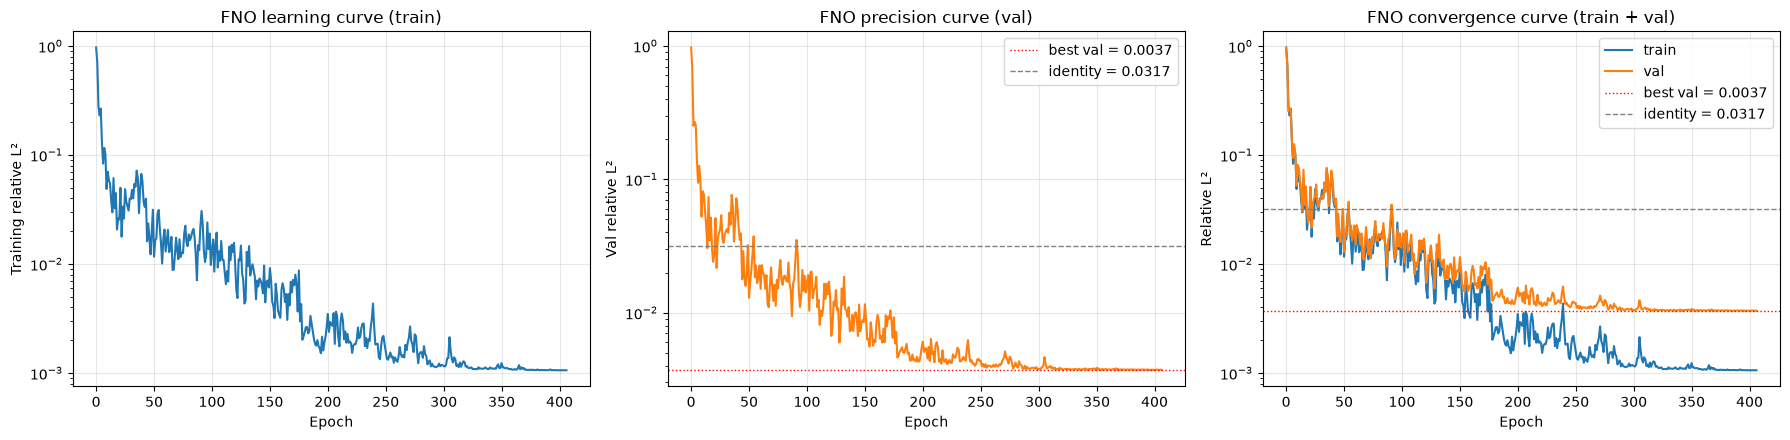

In [12]:
import matplotlib.pyplot as plt
train = np.array(train_curve)
val   = np.array(val_curve)
best  = best_val
epochs = np.arange(len(train))

# Identity baseline (predict u_next = u_now) on this run's validation split
with torch.no_grad():
    identity = rel_l2(X_val, Y_val).item()

# Save the history, like the CNN does with training_history.npz
np.savez(f'training_history_fno_modes{MODES}.npz', train=train, val=val, best=best)

# 3-panel figure: learning | precision | convergence
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# ---- Panel 1: Learning curve (training loss only) ----
axes[0].plot(epochs, train, color='C0', linewidth=1.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training relative L²')
axes[0].set_yscale('log')
axes[0].set_title('FNO learning curve (train)')
axes[0].grid(True, alpha=0.3)

# ---- Panel 2: Precision curve (validation loss only) ----
axes[1].plot(epochs, val, color='C1', linewidth=1.5)
axes[1].axhline(best, color='red', linestyle=':', linewidth=1,
                label=f'best val = {best:.4f}')
axes[1].axhline(identity, color='gray', linestyle='--', linewidth=1,
                label=f'identity = {identity:.4f}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Val relative L²')
axes[1].set_yscale('log')
axes[1].set_title('FNO precision curve (val)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ---- Panel 3: Convergence curve (train + val together) ----
axes[2].plot(epochs, train, label='train', color='C0', linewidth=1.5)
axes[2].plot(epochs, val, label='val', color='C1', linewidth=1.5)
axes[2].axhline(best, color='red', linestyle=':', linewidth=1,
                label=f'best val = {best:.4f}')
axes[2].axhline(identity, color='gray', linestyle='--', linewidth=1,
                label=f'identity = {identity:.4f}')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Relative L²')
axes[2].set_yscale('log')
axes[2].set_title('FNO convergence curve (train + val)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
device_eval = 'cpu'  
model_path  = f'fno_modes64_38traj_seed0.pt'

ckpt = torch.load(model_path, map_location=device_eval, weights_only=False)
model_eval = FNO1d(**ckpt['config']).to(device_eval)
model_eval.load_state_dict(ckpt['state'])
model_eval.eval()
print(f"Loaded {model_path}  (best epoch: {ckpt['best_epoch']})")

Loaded fno_modes64_38traj_seed0.pt  (best epoch: 366)


# Evaluate  at 128 256 512 grid points

In [14]:
def rel_l2_per_sample(pred, target):
    """NumPy version: returns one error value per example."""
    num = np.linalg.norm((pred - target).reshape(len(pred), -1), axis=1)
    den = np.linalg.norm(target.reshape(len(target), -1), axis=1) + 1e-8
    return num / den

In [17]:
DATA_DIR_EVAL = DATA_DIR 
results = {}
with torch.no_grad():
    for res in [128, 256, 512]:
        data_e = np.load(f"data/eval_{res}.npz")
        X_e = data_e['field'].astype(np.float32)
        Y_e = data_e['target'].astype(np.float32)

        X_t = torch.tensor(X_e, device=device_eval)
        pred = model_eval(make_input(X_t)).cpu().numpy()

        fno_err = rel_l2_per_sample(pred, Y_e)
        id_err  = rel_l2_per_sample(X_e, Y_e)   # identity baseline: predict no change (just for reference / no use)

        results[res] = {'fno': fno_err, 'identity': id_err}

        print(f"=== Resolution {res} ===")
        print(f"  FNO mean rel-L2   : {fno_err.mean():.6f}")
        print(f"  FNO median        : {np.median(fno_err):.6f}")
        print(f"  Identity baseline : {id_err.mean():.6f}")
        print(f"  Improvement factor: {id_err.mean() / fno_err.mean():.2f}x")
        print()

=== Resolution 128 ===
  FNO mean rel-L2   : 0.003480
  FNO median        : 0.000842
  Identity baseline : 0.032534
  Improvement factor: 9.35x

=== Resolution 256 ===
  FNO mean rel-L2   : 0.004325
  FNO median        : 0.002040
  Identity baseline : 0.032549
  Improvement factor: 7.53x

=== Resolution 512 ===
  FNO mean rel-L2   : 0.004549
  FNO median        : 0.002314
  Identity baseline : 0.032552
  Improvement factor: 7.16x



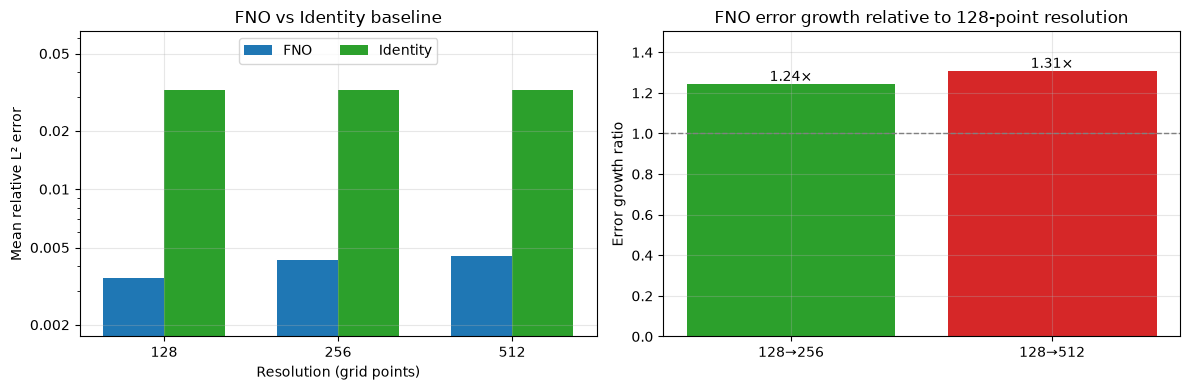

In [18]:
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

resolutions = [128, 256, 512]
fno_means = [results[r]['fno'].mean()      for r in resolutions]
id_means  = [results[r]['identity'].mean() for r in resolutions]
growth    = [fno_means[1] / fno_means[0], fno_means[2] / fno_means[0]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ---- Left: FNO vs identity baseline at each resolution ----
x = np.arange(len(resolutions))
w = 0.35
axes[0].bar(x - w/2, fno_means, w, label='FNO',      color='C0')
axes[0].bar(x + w/2, id_means,  w, label='Identity', color='C2')
axes[0].set_xticks(x)
axes[0].set_xticklabels([str(r) for r in resolutions])
axes[0].set_xlabel('Resolution (grid points)')
axes[0].set_ylabel('Mean relative L² error')
axes[0].set_yscale('log')
axes[0].set_ylim(min(fno_means) * 0.5, max(id_means) * 2)   # headroom for the legend
axes[0].yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
axes[0].yaxis.set_minor_formatter(NullFormatter())
axes[0].set_title('FNO vs Identity baseline')
axes[0].legend(loc='upper center', ncol=2)
axes[0].grid(True, alpha=0.3)

# ---- Right: how much the error grows off the training resolution ----
axes[1].bar(['128→256', '128→512'], growth, color=['C2', 'C3'])
axes[1].axhline(1.0, color='gray', linestyle='--', linewidth=1)
axes[1].set_ylabel('Error growth ratio')
axes[1].set_title('FNO error growth relative to 128-point resolution')
axes[1].set_ylim(0, max(growth) * 1.15)                     # room for the labels
for i, v in enumerate(growth):
    axes[1].text(i, v, f'{v:.2f}×', ha='center', va='bottom')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

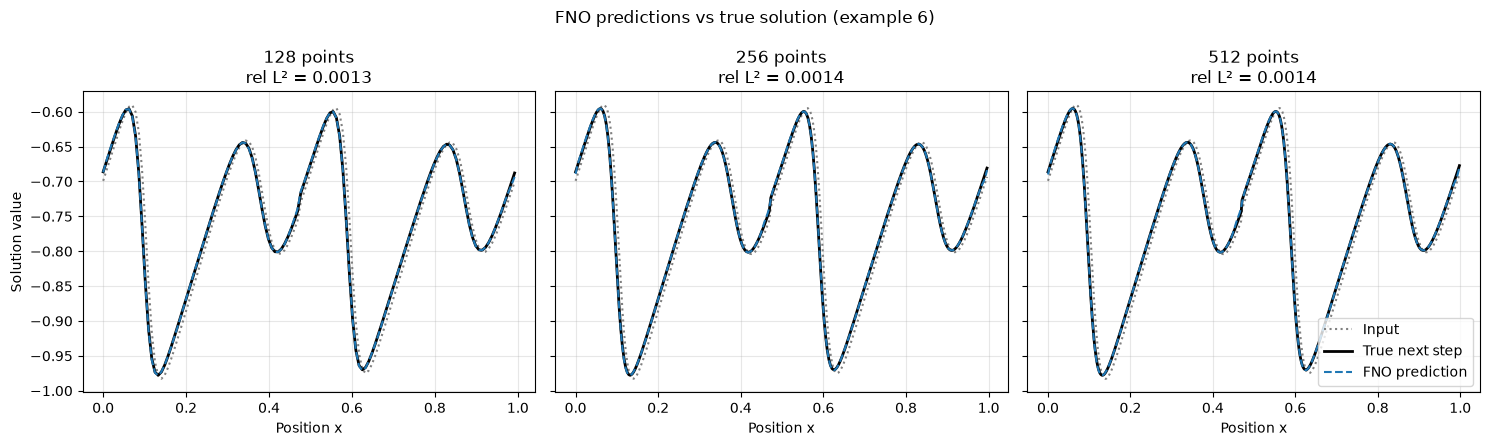

In [20]:
idx = 6   # which evaluation example to show
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

with torch.no_grad():
    for ax, res in zip(axes, [128, 256, 512]):
        data_e = np.load(f"data/eval_{res}.npz")
        u_in   = data_e['field'][idx].astype(np.float32)
        u_true = data_e['target'][idx].astype(np.float32)

        # Predict this one example: (N,) -> (1, N) -> model -> (N,)
        u_pred = model_eval(make_input(torch.tensor(u_in[None], device=device_eval)))[0].cpu().numpy()
        x = np.linspace(0, 1, res, endpoint=False)   # same grid make_input gives the model

        ax.plot(x, u_in,   ':',  color='gray',  linewidth=1.5, label='Input')
        ax.plot(x, u_true, '-',  color='black', linewidth=2,   label='True next step')
        ax.plot(x, u_pred, '--', color='C0',    linewidth=1.5, label='FNO prediction')
        ax.set_title(f"{res} points\nrel L² = {results[res]['fno'][idx]:.4f}")
        ax.set_xlabel('Position x')
        ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Solution value')
axes[-1].legend(loc='lower right')
fig.suptitle(f'FNO predictions vs true solution (example {idx})')
plt.tight_layout()
plt.show()

# Bucket Based Evaluations